# IFN680 — Project 7: Improving DDPM
## Reproducibility / inference notebook — `main_report.ipynb`

This notebook **loads the two pre-trained checkpoints** produced by `DDPM_CosineSchedule.ipynb` (Linear-schedule and Cosine-schedule conditional DDPMs) and reproduces every plot, number, and qualitative result referenced in the report. **It does not retrain any model** — only inference, evaluation, and plotting, so it can be re-run quickly by a grader to verify reproducibility.

Structure:
1. Load checkpoints (both DDPMs + auxiliary classifier + training logs)
2. Training summary (time, loss curves)
3. **Required deliverable:** full-length (T-step) conditional sampling — 12x10 grid (12 samples x 10 digits = 120 images) per schedule
4. Diversity / mode-collapse check
5. **Hypothesis test:** sample quality vs. number of reverse-process steps (accelerated/respaced sampling), linear vs. cosine
6. Summary numbers for the report

> **Before running:** make sure `mnist_custom.pt` and the `checkpoints/` folder (populated by `DDPM_CosineSchedule.ipynb`) are in the same directory as this notebook.

In [1]:
import os
import pickle

import torch
import numpy as np
import matplotlib.pyplot as plt

import ddpm_utils as U

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

DATA_PATH = "mnist_custom.pt"
CHECKPOINT_DIR = "checkpoints"
FIGURE_DIR = "figures"
os.makedirs(FIGURE_DIR, exist_ok=True)

Using device: cuda


## 1. Load trained models and schedules from checkpoints

In [2]:
model_linear, schedule_linear, ckpt_linear = U.load_ddpm_checkpoint(
    os.path.join(CHECKPOINT_DIR, "linear_ddpm.pt"), device
)
model_cosine, schedule_cosine, ckpt_cosine = U.load_ddpm_checkpoint(
    os.path.join(CHECKPOINT_DIR, "cosine_ddpm.pt"), device
)

image_size = ckpt_linear["image_size"]
channels = ckpt_linear["channels"]
timesteps = ckpt_linear["timesteps"]
n_classes = ckpt_linear["n_classes"]
assert ckpt_linear["image_size"] == ckpt_cosine["image_size"]
assert ckpt_linear["timesteps"] == ckpt_cosine["timesteps"]
print(f"Loaded both models. image_size={image_size}, timesteps={timesteps}, n_classes={n_classes}")

with open(os.path.join(CHECKPOINT_DIR, "linear_train_log.pkl"), "rb") as f:
    log_linear = pickle.load(f)
with open(os.path.join(CHECKPOINT_DIR, "cosine_train_log.pkl"), "rb") as f:
    log_cosine = pickle.load(f)

# Auxiliary classifier (quantitative evaluation only, not part of either DDPM)
clf_ckpt = torch.load(os.path.join(CHECKPOINT_DIR, "classifier.pt"), map_location=device)
classifier = U.DigitClassifier(channels=channels, n_classes=clf_ckpt["n_classes"], image_size=clf_ckpt["image_size"])
classifier.load_state_dict(clf_ckpt["state_dict"])
classifier.to(device).eval()
print("Loaded auxiliary classifier.")

Loaded both models. image_size=20, timesteps=1000, n_classes=10
Loaded auxiliary classifier.


In [3]:
# Real test images, used only as a visual reference and for classifier sanity-check
_, test_dataset = U.load_mnist_custom(DATA_PATH)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=256, shuffle=True)

## 2. Training summary

Loss curves and wall-clock training time for both runs (same architecture, hyperparameters, and epoch count — only the schedule differs). These numbers go directly into the report's Methodology/Discussion (training time is one of the two things the report asks you to discuss, alongside image quality).

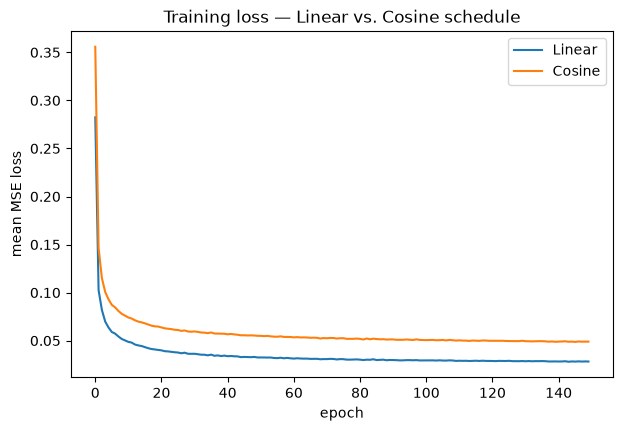

TRAINING SUMMARY
Metric                               Linear         Cosine
Epochs                                  150            150
Final epoch loss                    0.02826        0.04900
Training time (s)                     745.5          754.0
Training time (min)                   12.42          12.57


In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(log_linear["loss_history"], label="Linear")
ax.plot(log_cosine["loss_history"], label="Cosine")
ax.set_xlabel("epoch")
ax.set_ylabel("mean MSE loss")
ax.set_title("Training loss — Linear vs. Cosine schedule")
ax.legend()
plt.savefig(os.path.join(FIGURE_DIR, "loss_comparison.png"), dpi=150, bbox_inches="tight")
plt.show()

print("=" * 60)
print("TRAINING SUMMARY")
print("=" * 60)
print(f"{'Metric':<28}{'Linear':>15}{'Cosine':>15}")
print(f"{'Epochs':<28}{log_linear['epochs']:>15}{log_cosine['epochs']:>15}")
print(f"{'Final epoch loss':<28}{log_linear['loss_history'][-1]:>15.5f}{log_cosine['loss_history'][-1]:>15.5f}")
print(f"{'Training time (s)':<28}{log_linear['training_time']:>15.1f}{log_cosine['training_time']:>15.1f}")
print(f"{'Training time (min)':<28}{log_linear['training_time']/60:>15.2f}{log_cosine['training_time']/60:>15.2f}")

## 3. Required deliverable — full-length conditional sampling (12x10 grid, 120 images per model)

Standard DDPM ancestral sampling using **all `timesteps` reverse steps** (the same `T` both models were trained with). Labels are arranged as 12 consecutive samples per digit (0-9), so with `nrow=12` each **row** of the grid is one digit class and each **column** is an independent sample — a 12 (columns) x 10 (rows) grid, exactly as required.

Sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Sampling (1000 steps):   0%|          | 1/1000 [00:00<04:24,  3.77it/s]

Sampling (1000 steps):   4%|▎         | 37/1000 [00:00<00:07, 128.29it/s]

Sampling (1000 steps):   8%|▊         | 75/1000 [00:00<00:04, 211.96it/s]

Sampling (1000 steps):  10%|█         | 104/1000 [00:00<00:03, 227.35it/s]

Sampling (1000 steps):  13%|█▎        | 132/1000 [00:00<00:03, 237.54it/s]

... (26 outputs left out)

Sampling (1000 steps):  92%|█████████▏| 920/1000 [00:03<00:00, 241.40it/s]

Sampling (1000 steps):  95%|█████████▌| 954/1000 [00:03<00:00, 267.24it/s]

Sampling (1000 steps):  99%|█████████▉| 988/1000 [00:03<00:00, 286.83it/s]

Sampling (1000 steps): 100%|██████████| 1000/1000 [00:03<00:00, 253.60it/s]

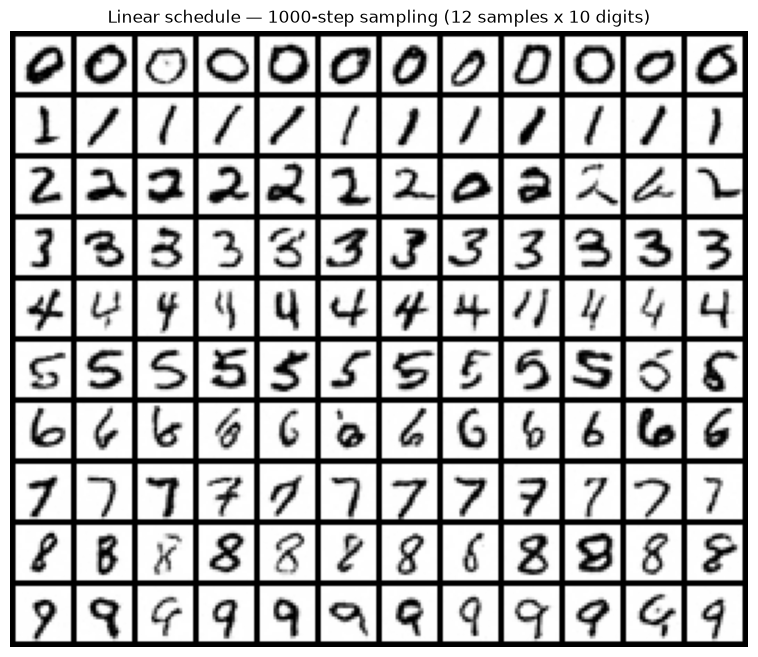

In [5]:
SAMPLES_PER_DIGIT = 12
full_labels = U.make_class_conditioned_labels(n_classes=n_classes, samples_per_class=SAMPLES_PER_DIGIT, device=device)
assert full_labels.shape[0] == n_classes * SAMPLES_PER_DIGIT  # 120 images

samples_linear_full = U.sample_ddpm(
    model_linear, schedule_linear, full_labels, image_size=image_size, channels=channels,
    num_steps=None, device=device, seed=1337,
)
U.plot_grid(samples_linear_full, nrow=SAMPLES_PER_DIGIT,
            title=f"Linear schedule — {timesteps}-step sampling (12 samples x 10 digits)",
            save_path=os.path.join(FIGURE_DIR, "grid_linear_full.png"))

Sampling (1000 steps):   0%|          | 0/1000 [00:00<?, ?it/s]

Sampling (1000 steps):   3%|▎         | 33/1000 [00:00<00:02, 329.36it/s]

Sampling (1000 steps):   7%|▋         | 66/1000 [00:00<00:03, 235.39it/s]

Sampling (1000 steps):   9%|▉         | 92/1000 [00:00<00:04, 203.47it/s]

Sampling (1000 steps):  11%|█▏        | 114/1000 [00:00<00:04, 195.89it/s]

Sampling (1000 steps):  14%|█▎        | 135/1000 [00:00<00:04, 194.11it/s]

... (21 outputs left out)

Sampling (1000 steps):  93%|█████████▎| 931/1000 [00:03<00:00, 213.69it/s]

Sampling (1000 steps):  96%|█████████▌| 961/1000 [00:03<00:00, 232.97it/s]

Sampling (1000 steps):  99%|█████████▊| 986/1000 [00:03<00:00, 218.31it/s]

Sampling (1000 steps): 100%|██████████| 1000/1000 [00:03<00:00, 281.62it/s]

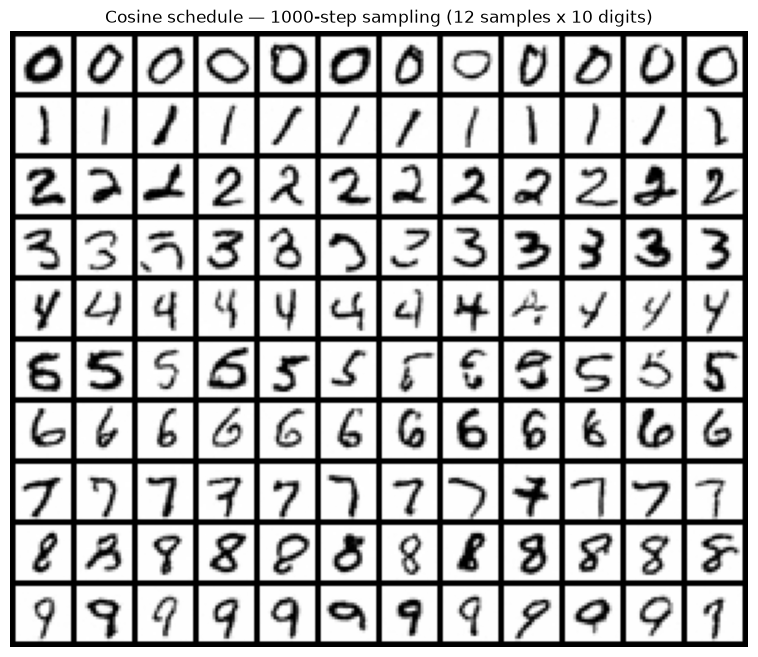

In [6]:
samples_cosine_full = U.sample_ddpm(
    model_cosine, schedule_cosine, full_labels, image_size=image_size, channels=channels,
    num_steps=None, device=device, seed=1337,
)
U.plot_grid(samples_cosine_full, nrow=SAMPLES_PER_DIGIT,
            title=f"Cosine schedule — {timesteps}-step sampling (12 samples x 10 digits)",
            save_path=os.path.join(FIGURE_DIR, "grid_cosine_full.png"))

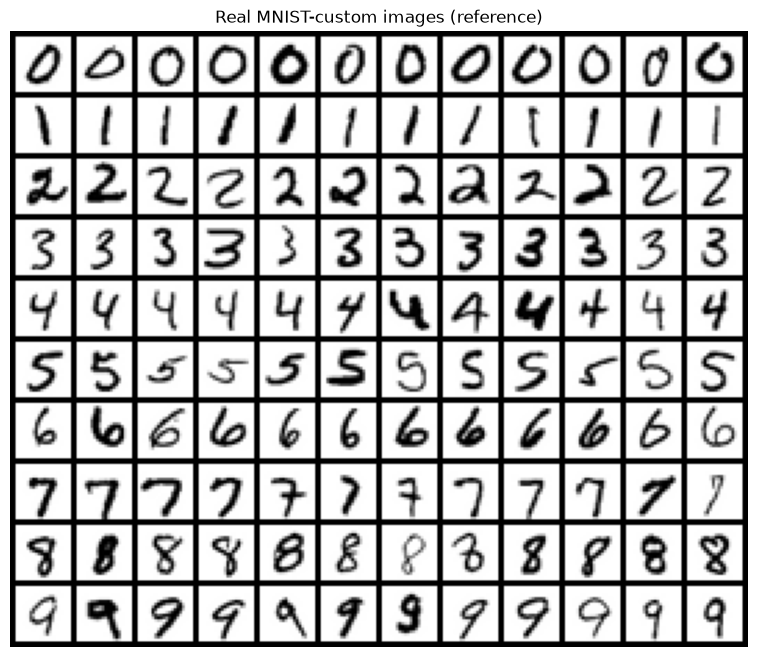

In [7]:
# Real reference images, for a visual quality benchmark
real_imgs, real_labels = next(iter(test_loader))
order = torch.argsort(real_labels)
real_imgs, real_labels = real_imgs[order], real_labels[order]

# take up to SAMPLES_PER_DIGIT real examples per digit
picked = []
for c in range(n_classes):
    idx = (real_labels == c).nonzero(as_tuple=True)[0][:SAMPLES_PER_DIGIT]
    picked.append(real_imgs[idx])
real_grid_imgs = torch.cat(picked, dim=0)
U.plot_grid(real_grid_imgs, nrow=SAMPLES_PER_DIGIT, title="Real MNIST-custom images (reference)",
            save_path=os.path.join(FIGURE_DIR, "grid_real_reference.png"))

## 4. Diversity / mode-collapse check

For each digit class, the standard deviation of the 12 generated samples (pixel-wise, then averaged) should be clearly greater than zero — confirming the model produces varied samples per class rather than collapsing to a single prototype per digit.

In [8]:
def per_class_diversity(samples, labels, n_classes):
    scores = []
    for c in range(n_classes):
        class_samples = samples[labels == c]
        scores.append(class_samples.std(dim=0).mean().item())
    return scores

div_linear = per_class_diversity(samples_linear_full, full_labels.cpu(), n_classes)
div_cosine = per_class_diversity(samples_cosine_full, full_labels.cpu(), n_classes)

print(f"{'Digit':<8}{'Linear std':>14}{'Cosine std':>14}")
for c in range(n_classes):
    print(f"{c:<8}{div_linear[c]:>14.4f}{div_cosine[c]:>14.4f}")
print(f"{'Mean':<8}{np.mean(div_linear):>14.4f}{np.mean(div_cosine):>14.4f}")

Digit       Linear std    Cosine std
0               0.3186        0.3101
1               0.1451        0.1398
2               0.3304        0.3133
3               0.2811        0.3105
4               0.2371        0.2229
5               0.3208        0.3238
6               0.2598        0.2436
7               0.2155        0.2402
8               0.2618        0.2646
9               0.2439        0.2505
Mean            0.2614        0.2619


## 5. Testing the hypothesis: sample quality vs. number of reverse-process steps

This is the core experiment. Both models were **trained** with `timesteps` steps, but at **inference** time we can evaluate them with a subset of those steps using an accelerated / "respaced" DDPM sampler (`U.sample_ddpm(..., num_steps=K)`, see `ddpm_utils.py`): the model is still queried with its original timestep embeddings, but the reverse process only takes `K` steps instead of `timesteps`. This directly tests the hypothesis — *does the cosine schedule keep producing recognisable, good-quality digits with fewer steps than the linear schedule?*

Quality is scored two ways:
- **Quantitative:** the auxiliary classifier's accuracy on generated images (does the image actually look like the digit it was conditioned on?).
- **Qualitative:** side-by-side grids at a few representative step counts.

In [9]:
STEP_COUNTS = [1000, 500, 250, 100, 50, 20, 10, 5]
STEP_COUNTS = sorted(set(min(s, timesteps) for s in STEP_COUNTS), reverse=True)
SAMPLES_PER_DIGIT_EVAL = 8  # smaller than 12 to keep this sweep fast; increase if GPU time allows

eval_labels = U.make_class_conditioned_labels(n_classes=n_classes, samples_per_class=SAMPLES_PER_DIGIT_EVAL, device=device)

accuracy_linear, accuracy_cosine = [], []
for k in STEP_COUNTS:
    s_lin = U.sample_ddpm(model_linear, schedule_linear, eval_labels, image_size=image_size,
                           channels=channels, num_steps=k, device=device, seed=2024, show_progress=False)
    s_cos = U.sample_ddpm(model_cosine, schedule_cosine, eval_labels, image_size=image_size,
                           channels=channels, num_steps=k, device=device, seed=2024, show_progress=False)

    acc_lin = U.classifier_accuracy(classifier, s_lin, eval_labels.cpu(), device)
    acc_cos = U.classifier_accuracy(classifier, s_cos, eval_labels.cpu(), device)
    accuracy_linear.append(acc_lin)
    accuracy_cosine.append(acc_cos)
    print(f"steps={k:>5} | linear acc={acc_lin*100:6.2f}% | cosine acc={acc_cos*100:6.2f}%")

steps= 1000 | linear acc= 96.25% | cosine acc= 92.50%


steps=  500 | linear acc= 92.50% | cosine acc= 96.25%


steps=  250 | linear acc=100.00% | cosine acc= 96.25%


steps=  100 | linear acc= 97.50% | cosine acc= 96.25%


steps=   50 | linear acc= 96.25% | cosine acc= 93.75%
steps=   20 | linear acc= 93.75% | cosine acc= 93.75%


steps=   10 | linear acc= 82.50% | cosine acc= 86.25%
steps=    5 | linear acc= 62.50% | cosine acc= 57.50%


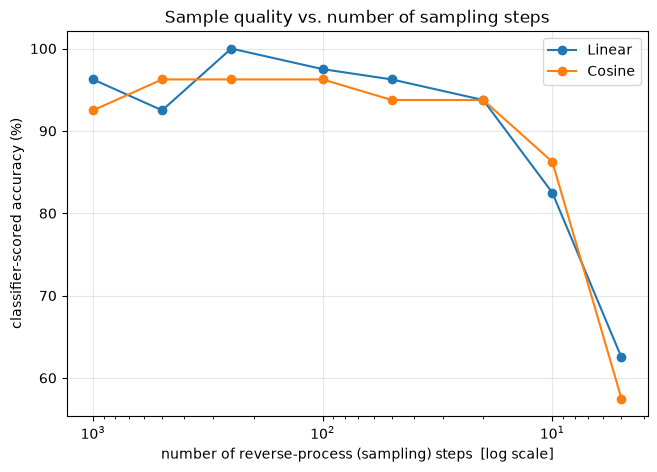

In [10]:
plt.figure(figsize=(7.5, 5))
plt.plot(STEP_COUNTS, np.array(accuracy_linear) * 100, "o-", label="Linear")
plt.plot(STEP_COUNTS, np.array(accuracy_cosine) * 100, "o-", label="Cosine")
plt.xscale("log")
plt.gca().invert_xaxis()
plt.xlabel("number of reverse-process (sampling) steps  [log scale]")
plt.ylabel("classifier-scored accuracy (%)")
plt.title("Sample quality vs. number of sampling steps")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig(os.path.join(FIGURE_DIR, "accuracy_vs_steps.png"), dpi=150, bbox_inches="tight")
plt.show()

### Qualitative comparison at representative step counts

Same seed, same labels, same models — only `num_steps` differs — so any visual degradation is attributable to the reduced number of reverse steps.

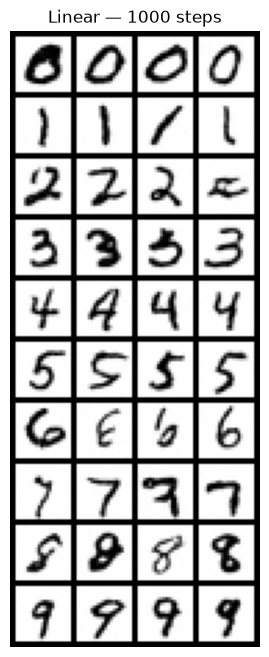

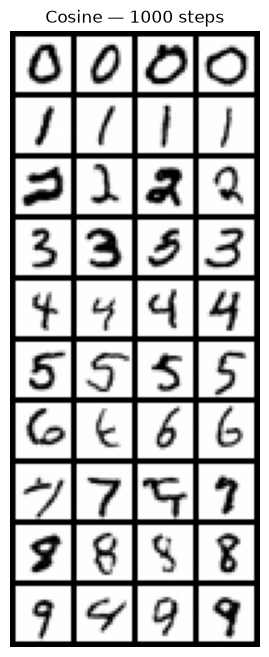

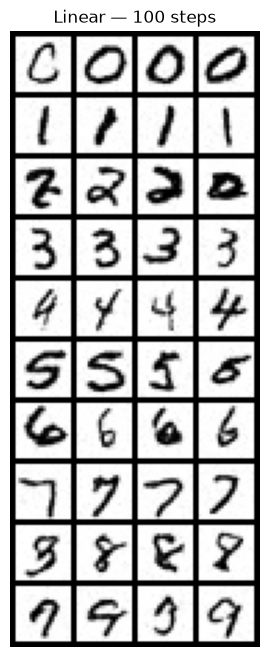

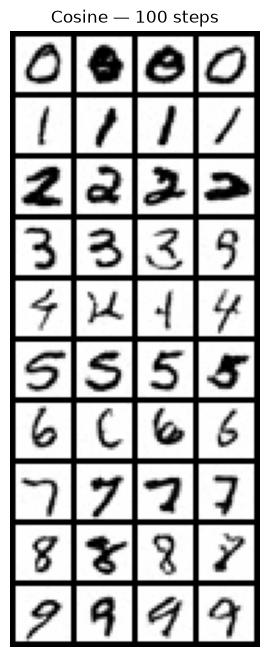

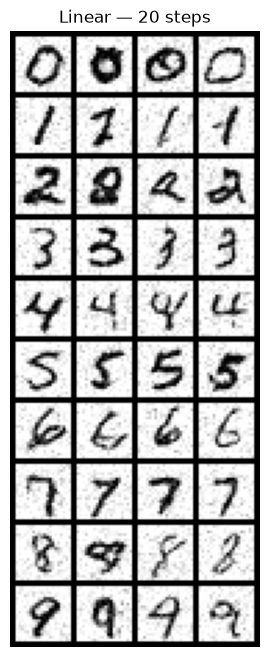

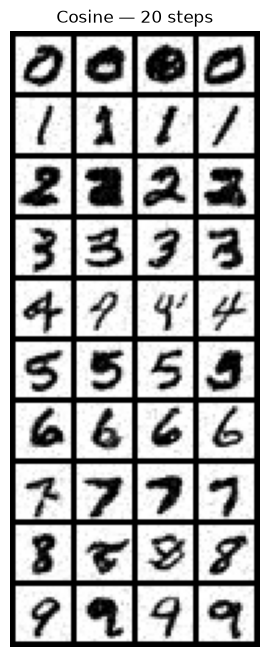

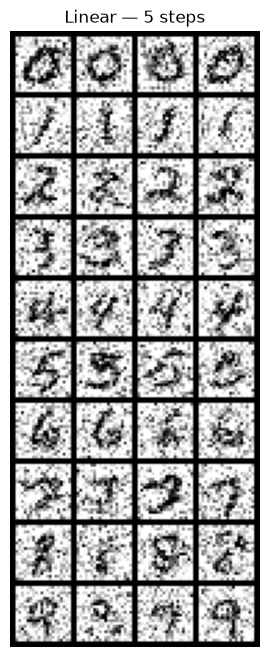

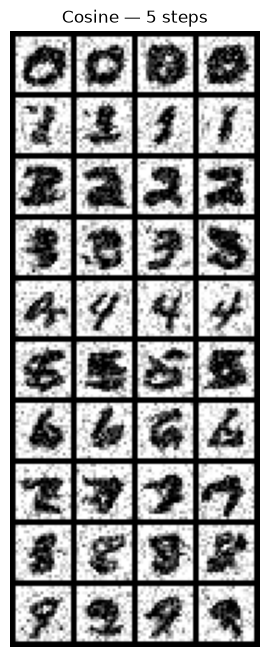

In [11]:
REPRESENTATIVE_STEPS = [s for s in [timesteps, max(1, timesteps // 10), 20, 5] if s <= timesteps]
REPRESENTATIVE_STEPS = sorted(set(REPRESENTATIVE_STEPS), reverse=True)
qual_labels = U.make_class_conditioned_labels(n_classes=n_classes, samples_per_class=4, device=device)

for k in REPRESENTATIVE_STEPS:
    s_lin = U.sample_ddpm(model_linear, schedule_linear, qual_labels, image_size=image_size,
                           channels=channels, num_steps=k, device=device, seed=7, show_progress=False)
    U.plot_grid(s_lin, nrow=4, title=f"Linear — {k} steps",
                save_path=os.path.join(FIGURE_DIR, f"grid_linear_{k}steps.png"))

    s_cos = U.sample_ddpm(model_cosine, schedule_cosine, qual_labels, image_size=image_size,
                           channels=channels, num_steps=k, device=device, seed=7, show_progress=False)
    U.plot_grid(s_cos, nrow=4, title=f"Cosine — {k} steps",
                save_path=os.path.join(FIGURE_DIR, f"grid_cosine_{k}steps.png"))

## 6. Summary numbers for the report

Everything below is what you need to fill the report's tables/figures — see `report_README.md`.

In [12]:
print("=" * 64)
print("REPORT SUMMARY NUMBERS")
print("=" * 64)
print(f"Timesteps used for training (T):          {timesteps}")
print(f"Epochs:                                    {log_linear['epochs']}")
print()
print(f"Training time — Linear:                    {log_linear['training_time']:.1f}s "
      f"({log_linear['training_time']/60:.2f} min)")
print(f"Training time — Cosine:                     {log_cosine['training_time']:.1f}s "
      f"({log_cosine['training_time']/60:.2f} min)")
print()
print(f"Final training loss — Linear:               {log_linear['loss_history'][-1]:.5f}")
print(f"Final training loss — Cosine:                {log_cosine['loss_history'][-1]:.5f}")
print()
print(f"Mean sample diversity (std) — Linear:       {np.mean(div_linear):.4f}")
print(f"Mean sample diversity (std) — Cosine:        {np.mean(div_cosine):.4f}")
print()
print(f"Classifier accuracy @ full T ({timesteps} steps) — Linear: {accuracy_linear[0]*100:.2f}%")
print(f"Classifier accuracy @ full T ({timesteps} steps) — Cosine: {accuracy_cosine[0]*100:.2f}%")
print()
print("Classifier accuracy across step counts:")
print(f"{'steps':>8}{'linear %':>12}{'cosine %':>12}")
for k, a_l, a_c in zip(STEP_COUNTS, accuracy_linear, accuracy_cosine):
    print(f"{k:>8}{a_l*100:>12.2f}{a_c*100:>12.2f}")

REPORT SUMMARY NUMBERS
Timesteps used for training (T):          1000
Epochs:                                    150

Training time — Linear:                    745.5s (12.42 min)
Training time — Cosine:                     754.0s (12.57 min)

Final training loss — Linear:               0.02826
Final training loss — Cosine:                0.04900

Mean sample diversity (std) — Linear:       0.2614
Mean sample diversity (std) — Cosine:        0.2619

Classifier accuracy @ full T (1000 steps) — Linear: 96.25%
Classifier accuracy @ full T (1000 steps) — Cosine: 92.50%

Classifier accuracy across step counts:
   steps    linear %    cosine %
    1000       96.25       92.50
     500       92.50       96.25
     250      100.00       96.25
     100       97.50       96.25
      50       96.25       93.75
      20       93.75       93.75
      10       82.50       86.25
       5       62.50       57.50


---
### Figures saved to `figures/`

- `loss_comparison.png` — training loss, linear vs. cosine
- `grid_linear_full.png`, `grid_cosine_full.png` — required 12x10 (120-image) grids at full `T`
- `grid_real_reference.png` — real reference images
- `accuracy_vs_steps.png` — **key hypothesis-test figure**: classifier accuracy vs. number of sampling steps
- `grid_linear_{k}steps.png`, `grid_cosine_{k}steps.png` — qualitative grids at representative step counts

Use these figures and the printed summary numbers above to fill in the Word report — see `report_README.md` for exactly where each one goes.